# Assignment 1 — Question 1.2

In [7]:
import os

# Go to the folder that contains train.py.
# Locally: this notebook is in notebooks/ and train.py is in ../student.
# On Colab: upload the student files next to the notebook (nothing happens here).
if os.path.isdir("../student"):
    os.chdir("../student")

## 1.2.1 — Test metrics

**(3 points)** For every combination of dataset, model, and (context, horizon) setting, report the test `MSE` and test `MAE`.

For the noisy datasets, you have access to both the noisy targets and the underlying noiseless ground truth. In addition to the metrics above, compute `gt_test_mse` and `gt_test_mae`: the MSE and MAE of each model's predictions evaluated against the *noiseless* ground truth, rather than the noisy targets. These metrics measure how well a model recovers the true underlying signal, i.e. how good a denoiser it is.

In [9]:
# Runs all the experiments (20 datasets x 5 models x 3 settings = 300 runs)
# with the default settings of train.py, and saves results/results.csv.
# This takes a while.
%run train.py

sine_slow | MLP_2_ReLU | ctx=96, p=336:   0%|          | 1/300 [00:00<03:18,  1.51run/s]

[sine_slow | MLP_1 | ctx=96, p=336] test_mse=7.196e-09 test_mae=6.964e-05


sine_slow | MLP_2_Sigmoid_MSE | ctx=96, p=336:   1%|          | 2/300 [00:01<03:42,  1.34run/s]

[sine_slow | MLP_2_ReLU | ctx=96, p=336] test_mse=0.003964 test_mae=0.05011


sine_slow | MLP_2_Sigmoid_MAE | ctx=96, p=336:   1%|          | 3/300 [00:02<03:56,  1.26run/s]

[sine_slow | MLP_2_Sigmoid_MSE | ctx=96, p=336] test_mse=0.07767 test_mae=0.2458


... (590 outputs left out)

expo_trend_noisy_snr-10db | MLP_2_Tanh | ctx=336, p=720: 100%|█████████▉| 299/300 [04:34<00:01,  1.03s/run]       

[expo_trend_noisy_snr-10db | MLP_2_Sigmoid_MAE | ctx=336, p=720] test_mse=2.034e+09 test_mae=3.602e+04


expo_trend_noisy_snr-10db | MLP_2_Tanh | ctx=336, p=720: 100%|██████████| 300/300 [04:35<00:00,  1.09run/s]


[expo_trend_noisy_snr-10db | MLP_2_Tanh | ctx=336, p=720] test_mse=2.11e+09 test_mae=3.666e+04
sine_slow_noisy_snr20db: best=MLP_1 (ctx=96, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
sine_slow_noisy_snr0db: best=MLP_2_Tanh (ctx=336, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
sine_slow_noisy_snr-10db: best=MLP_2_Sigmoid_MSE (ctx=96, p=336) | worst=MLP_1 (ctx=336, p=336)
sine_fast_noisy_snr20db: best=MLP_1 (ctx=96, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
sine_fast_noisy_snr0db: best=MLP_2_Tanh (ctx=336, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
sine_fast_noisy_snr-10db: best=MLP_2_Sigmoid_MSE (ctx=96, p=336) | worst=MLP_1 (ctx=336, p=336)
linear_trend_noisy_snr20db: best=MLP_1 (ctx=96, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
linear_trend_noisy_snr0db: best=MLP_2_ReLU (ctx=96, p=336) | worst=MLP_2_Sigmoid_MAE (ctx=336, p=720)
linear_trend_noisy_snr-10db: best=MLP_2_Tanh (ctx=336, p=336) | worst=MLP_1 (ctx=336, p=336)
quadra_trend_noisy_snr20db: be

In [10]:
import pandas as pd

pd.set_option("display.max_rows", None)  # show every row

# The gt_test_* columns are empty (NaN) for the clean datasets.
df = pd.read_csv("results/results.csv")
df

,dataset,model,context,horizon,test_mse,test_mae,gt_test_mse,gt_test_mae
0,sine_slow,MLP_1,96,336,7.196175e-09,6.964147e-05,NaN,NaN
1,sine_slow,MLP_2_ReLU,96,336,3.963658e-03,5.010993e-02,NaN,NaN
2,sine_slow,MLP_2_Sigmoid_MSE,96,336,7.767148e-02,2.457749e-01,NaN,NaN
3,sine_slow,MLP_2_Sigmoid_MAE,96,336,2.350574e-01,4.231481e-01,NaN,NaN
4,sine_slow,MLP_2_Tanh,96,336,3.020725e-03,4.378286e-02,NaN,NaN
5,sine_slow,MLP_1,336,336,2.414843e-09,3.980292e-05,NaN,NaN
6,sine_slow,MLP_2_ReLU,336,336,3.475961e-03,4.734475e-02,NaN,NaN
7,sine_slow,MLP_2_Sigmoid_MSE,336,336,5.854678e-02,2.119372e-01,NaN,NaN
8,sine_slow,MLP_2_Sigmoid_MAE,336,336,1.771271e-01,3.579848e-01,NaN,NaN
9,sine_slow,MLP_2_Tanh,336,336,3.373804e-03,4.607702e-02,NaN,NaN


## 1.2.2 — Best and worst models

**(3 points)** Using `gt_test_mse` and `gt_test_mae`, identify the best- and worst-performing models on each dataset and plot their predictions. Are these results consistent with what you would expect based on the depth and choice of activation function of each model?

**My initial expectations:** Based on my understanding, `MLP_1` is a single linear layer that maps past points to future points. The other models use a nonlinear activation in a hidden layer, followed by a linear output layer. Sigmoid and tanh can saturate: their hidden outputs change very little when their pre-activation values are very large or very small, and their gradients approach zero in these regions. ReLU can grow without an upper limit for positive pre-activation values, but its output and gradient are zero for negative values. For the sinusoidal datasets, future values of a fixed-frequency sinusoid can be expressed as linear combinations of past values. I therefore expect a linear mapping (`MLP_1`) to be sufficient and to perform well. Tanh is centered around zero, which may help with zero-centered patterns, but this does not imply that it will perform best. For the increasing curves, I expect sigmoid and tanh to be less precise when extrapolating beyond the training range, because their hidden units may saturate on test inputs. `MLP_1` and ReLU are plausible candidates for better performance, although this is not guaranteed. As the SNR decreases, the noise becomes stronger, making the clean underlying curve harder to recover; I therefore expect the ground-truth errors to increase. For MSE versus MAE, MSE penalizes large errors more strongly, whereas MAE grows proportionally to the absolute error. Since both sigmoid models use the same activation, saturation can affect both; I do not expect MAE to perform better solely because of sigmoid saturation.


In [11]:
# 1.2.2 - best and worst run on each noisy dataset, for each ground-truth metric.
# A "run" is one (model, context, horizon) combination, so each dataset has 5 x 3 = 15 candidates.
noisy = df.dropna(subset=["gt_test_mse", "gt_test_mae"])
GT_METRICS = ["gt_test_mse", "gt_test_mae"]

rows, n_ties = [], 0
for dataset, g in noisy.groupby("dataset", sort=False):
    for metric in GT_METRICS:
        best, worst = g.loc[g[metric].idxmin()], g.loc[g[metric].idxmax()]
        n_ties += int((g[metric] == best[metric]).sum() > 1) + int((g[metric] == worst[metric]).sum() > 1)
        rows.append({
            "dataset": dataset, "metric": metric,
            "best_model": best["model"], "best_h/p": f"{int(best['context'])}/{int(best['horizon'])}", "best_value": best[metric],
            "worst_model": worst["model"], "worst_h/p": f"{int(worst['context'])}/{int(worst['horizon'])}", "worst_value": worst[metric],
        })
summary = pd.DataFrame(rows)

print(f"{len(noisy)} runs on {noisy['dataset'].nunique()} noisy datasets; ties for best/worst: {n_ties}")
for metric, s in summary.groupby("metric"):
    print(f"\n{metric}")
    print("  best :", s["best_model"].value_counts().to_dict())
    print("  worst:", s["worst_model"].value_counts().to_dict())

summary

225 runs on 15 noisy datasets; ties for best/worst: 0

gt_test_mae
  best : {'MLP_1': 6, 'MLP_2_Tanh': 5, 'MLP_2_Sigmoid_MSE': 3, 'MLP_2_ReLU': 1}
  worst: {'MLP_2_Sigmoid_MAE': 10, 'MLP_1': 5}

gt_test_mse
  best : {'MLP_1': 6, 'MLP_2_Sigmoid_MSE': 5, 'MLP_2_Tanh': 3, 'MLP_2_ReLU': 1}
  worst: {'MLP_2_Sigmoid_MAE': 9, 'MLP_1': 6}


,dataset,metric,best_model,best_h/p,best_value,worst_model,worst_h/p,worst_value
0,sine_slow_noisy_snr20db,gt_test_mse,MLP_1,96/336,2.257592e-03,MLP_2_Sigmoid_MAE,336/720,3.793349e-01
1,sine_slow_noisy_snr20db,gt_test_mae,MLP_1,96/336,3.785699e-02,MLP_2_Sigmoid_MAE,336/720,5.462225e-01
2,sine_slow_noisy_snr0db,gt_test_mse,MLP_2_Tanh,336/336,3.560640e-02,MLP_2_Sigmoid_MAE,336/720,4.634296e-01
3,sine_slow_noisy_snr0db,gt_test_mae,MLP_2_Tanh,336/336,1.501857e-01,MLP_2_Sigmoid_MAE,336/720,6.043900e-01
4,sine_slow_noisy_snr-10db,gt_test_mse,MLP_2_Sigmoid_MSE,96/336,5.366813e-01,MLP_1,336/336,3.404018e+00
5,sine_slow_noisy_snr-10db,gt_test_mae,MLP_2_Sigmoid_MSE,336/336,6.332903e-01,MLP_1,336/336,1.470586e+00
6,sine_fast_noisy_snr20db,gt_test_mse,MLP_1,96/336,2.537374e-03,MLP_2_Sigmoid_MAE,336/720,3.846841e-01
7,sine_fast_noisy_snr20db,gt_test_mae,MLP_1,96/336,4.009941e-02,MLP_2_Sigmoid_MAE,336/720,5.497524e-01
8,sine_fast_noisy_snr0db,gt_test_mse,MLP_2_Tanh,336/336,3.611599e-02,MLP_2_Sigmoid_MAE,336/720,4.696623e-01
9,sine_fast_noisy_snr0db,gt_test_mae,MLP_2_Tanh,336/336,1.515193e-01,MLP_2_Sigmoid_MAE,336/720,6.082534e-01


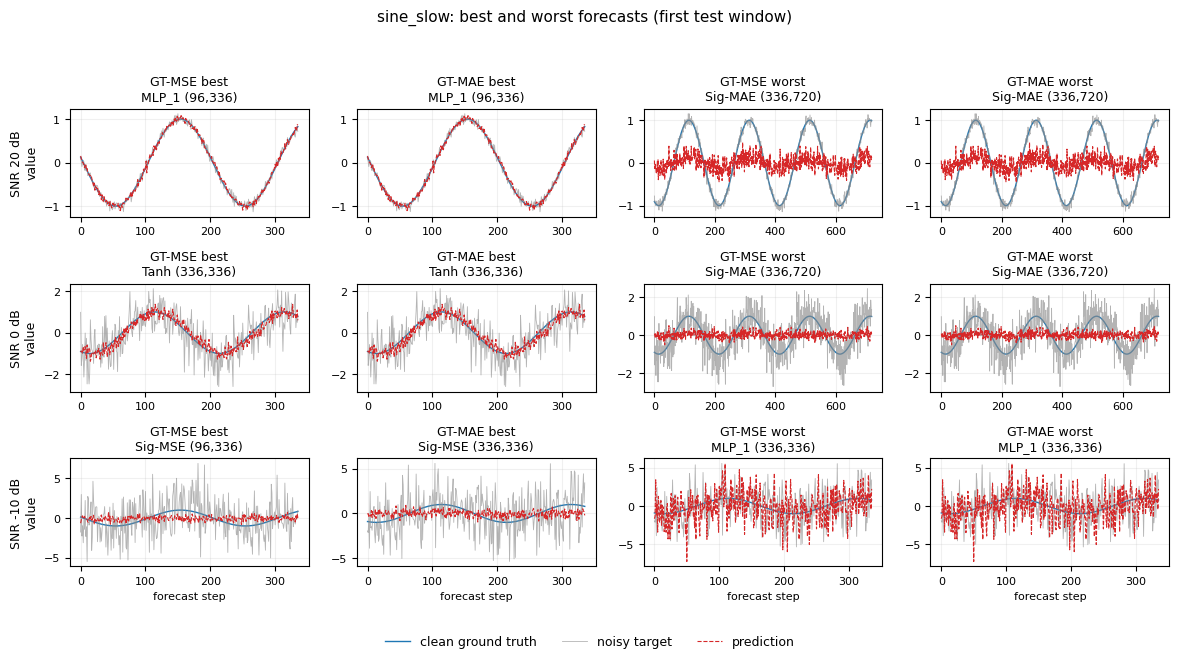

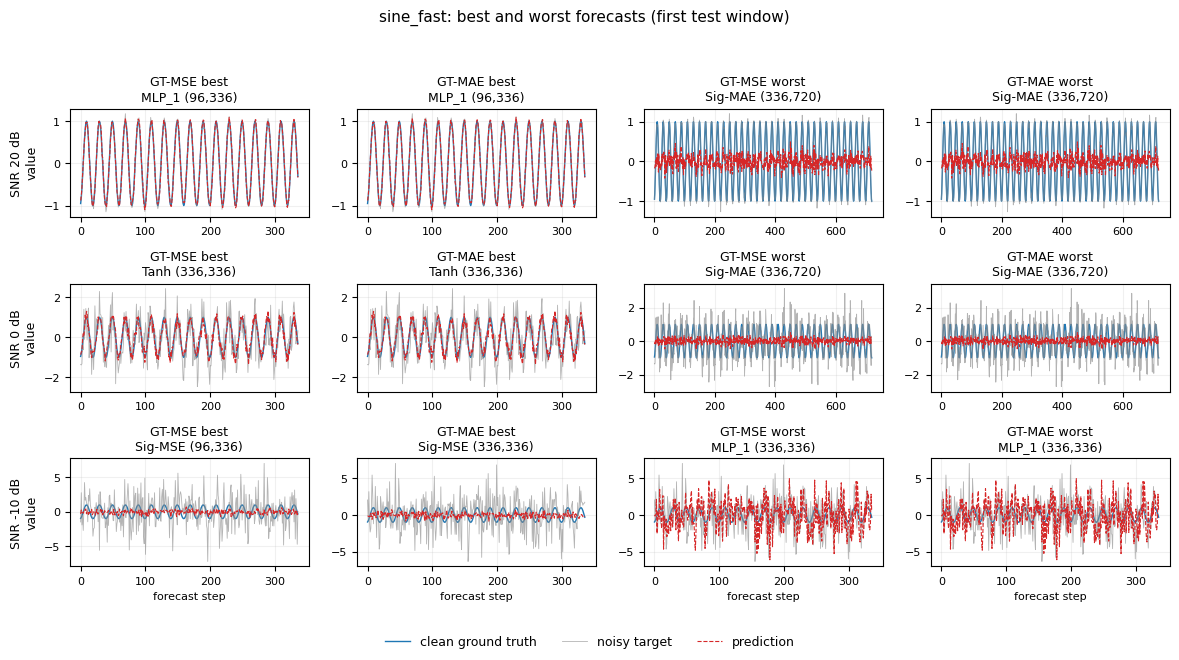

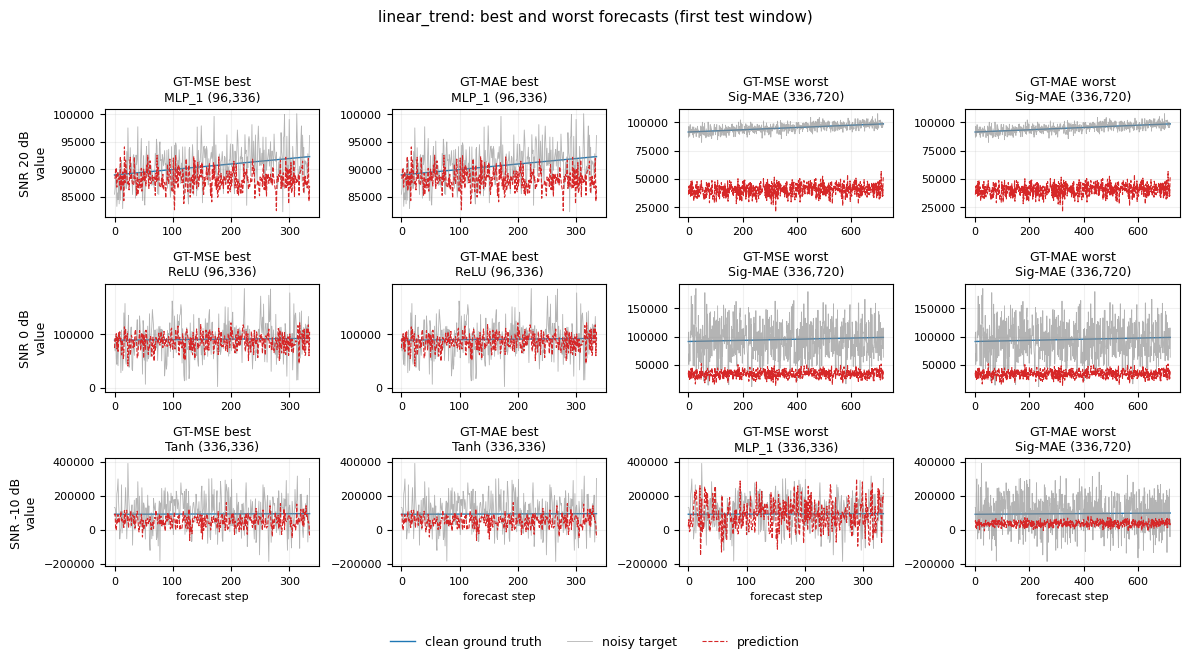

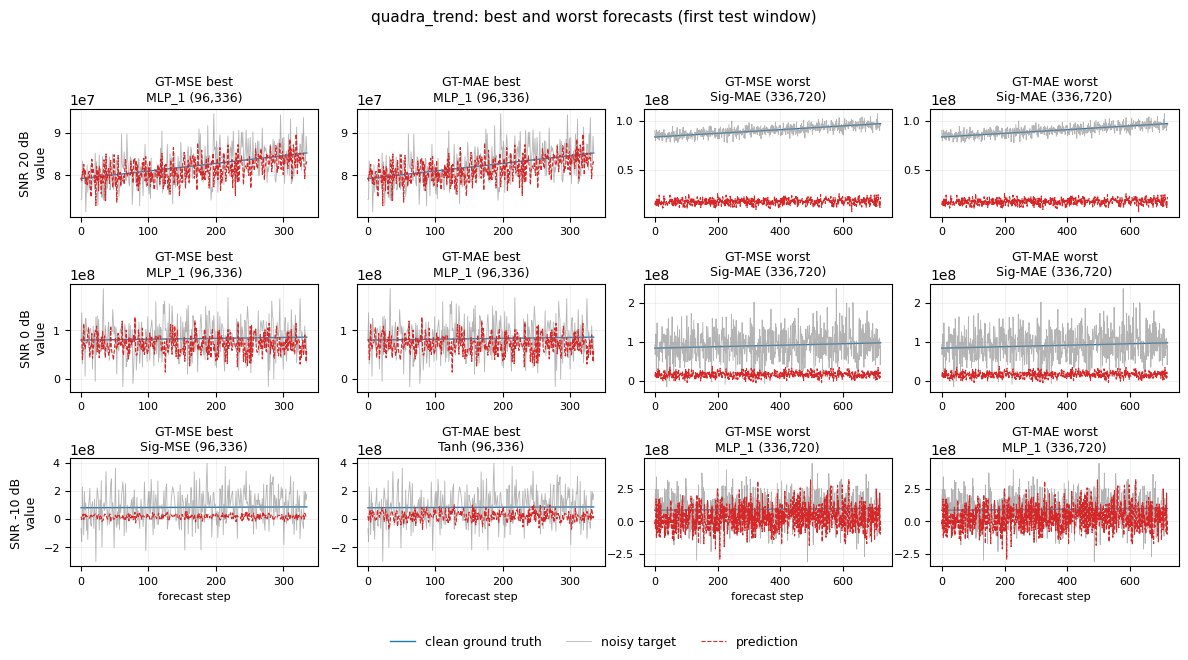

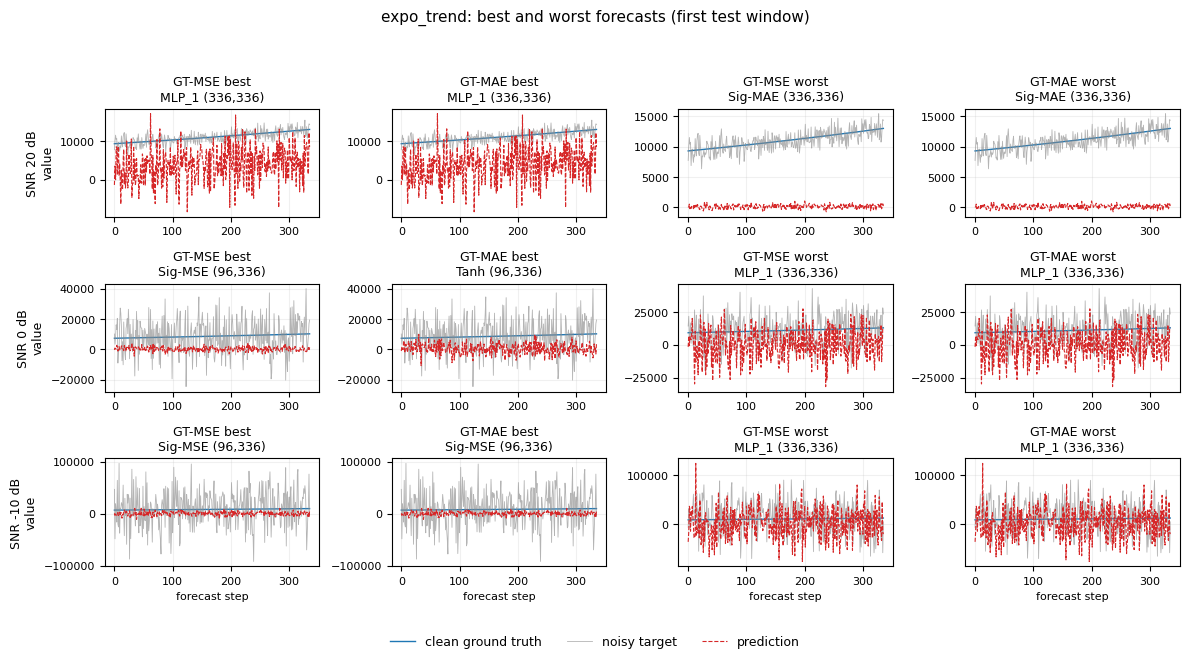

35 distinct runs plotted; all reproduce the values in results.csv.


In [12]:
import contextlib
import io

import matplotlib.pyplot as plt
import numpy as np

from data import ALL_DATASET_NAMES, BASE_DATASET_NAMES, N_POINTS, TimeSeriesDataset
from train import run_experiment

# Prediction plots of every selected run (best/worst for each ground-truth metric).
# Each run is re-trained with the default settings of train.py (seed 0, 15 epochs, batch size 128,
# lr 0.05; dataset i of ALL_DATASET_NAMES uses seed i) and checked against results.csv.
SHORT = {"MLP_1": "MLP_1", "MLP_2_ReLU": "ReLU", "MLP_2_Sigmoid_MSE": "Sig-MSE",
         "MLP_2_Sigmoid_MAE": "Sig-MAE", "MLP_2_Tanh": "Tanh"}
COLUMNS = [("gt_test_mse", "best"), ("gt_test_mae", "best"), ("gt_test_mse", "worst"), ("gt_test_mae", "worst")]
cache = {}


def get_run(dataset, model, hp):
    key = (dataset, model, hp)
    if key not in cache:
        context, horizon = map(int, hp.split("/"))
        ds = TimeSeriesDataset(name=dataset, n_points=N_POINTS, seed=ALL_DATASET_NAMES.index(dataset))
        with contextlib.redirect_stderr(io.StringIO()):  # hide the tqdm bars
            cache[key] = run_experiment(dataset, ds, model, context, horizon,
                                        epochs=15, batch_size=128, lr=0.05, seed=0)
    return cache[key]


os.makedirs("results/denoisers", exist_ok=True)
for family in BASE_DATASET_NAMES:
    fig, axes = plt.subplots(3, 4, figsize=(12, 6.6))
    for r, snr in enumerate([20, 0, -10]):
        dataset = f"{family}_noisy_snr{snr}db"
        for c, (metric, role) in enumerate(COLUMNS):
            row = summary[(summary["dataset"] == dataset) & (summary["metric"] == metric)].iloc[0]
            model, hp, value = row[f"{role}_model"], row[f"{role}_h/p"], row[f"{role}_value"]
            res = get_run(dataset, model, hp)
            assert np.isclose(res[metric], value, rtol=1e-9), (dataset, model, hp, metric)  # same run as results.csv
            ax = axes[r, c]
            ax.plot(res["test_target_clean"][0], color="C0", linewidth=1.0, label="clean ground truth")
            ax.plot(res["test_target"][0], color="0.55", linewidth=0.6, alpha=0.65, label="noisy target")
            ax.plot(res["test_pred"][0], color="C3", linewidth=0.8, linestyle="--", label="prediction")
            ax.set_title(f"GT-{metric[-3:].upper()} {role}\n{SHORT[model]} ({hp.replace('/', ',')})", fontsize=9)
            ax.tick_params(axis="both", labelsize=8)
            ax.grid(alpha=0.18)
            if c == 0:
                ax.set_ylabel(f"SNR {snr} dB\nvalue", fontsize=9)
            if r == 2:
                ax.set_xlabel("forecast step", fontsize=8)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, frameon=False)
    fig.suptitle(f"{family}: best and worst forecasts (first test window)", fontsize=11)
    fig.tight_layout(rect=[0, 0.06, 1, 0.95], w_pad=0.8, h_pad=1.0)
    fig.savefig(f"results/denoisers/q1_2_2_{family}_mse_mae_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()
print(f"{len(cache)} distinct runs plotted; all reproduce the values in results.csv.")

In [13]:
from train import MODEL_SPECS, build_model, train_model
from utils import make_windows, standardize_stats

# (a) Sigmoid trained with MSE vs trained with MAE: how often is the MSE-trained one better?
sig = noisy[noisy["model"].isin(["MLP_2_Sigmoid_MSE", "MLP_2_Sigmoid_MAE"])]
pivot = sig.pivot_table(index=["dataset", "context", "horizon"], columns="model", values=GT_METRICS)
for metric in GT_METRICS:
    wins = int((pivot[(metric, "MLP_2_Sigmoid_MSE")] < pivot[(metric, "MLP_2_Sigmoid_MAE")]).sum())
    print(f"{metric}: Sigmoid_MSE beats Sigmoid_MAE in {wins}/{len(pivot)} dataset/setting pairs")

# (b) Reference: constant predictor equal to the training mean, scored with gt_test_mse on the same windows.
ref = []
for dataset, g in noisy.groupby("dataset", sort=False):
    b = g.loc[g["gt_test_mse"].idxmin()]
    ds = TimeSeriesDataset(name=dataset, n_points=N_POINTS, seed=ALL_DATASET_NAMES.index(dataset))
    mean, std = standardize_stats(ds.train)
    _, Y_clean = make_windows((ds.clean_test - mean) / std, int(b["context"]), int(b["horizon"]))
    constant_mse = float(np.mean((Y_clean * std) ** 2))  # (clean target - training mean)^2
    ref.append({"dataset": dataset, "best_gt_test_mse": b["gt_test_mse"],
                "constant_predictor": constant_mse, "ratio": b["gt_test_mse"] / constant_mse})
print("\n(b) best run vs constant predictor (ratio close to 1 = no better than predicting the mean)")
print(pd.DataFrame(ref).to_string(index=False, float_format=lambda x: f"{x:.4g}"))


# (c) Saturation and under-fitting (context 96, horizon 336, SNR 20 dB). Values are in standardized units.
def diagnose(dataset, model_name, context=96, horizon=336):
    ds = TimeSeriesDataset(name=dataset, n_points=N_POINTS, seed=ALL_DATASET_NAMES.index(dataset))
    np.random.seed(0)  # Glorot initialization, as in run_experiment
    mean, std = standardize_stats(ds.train)
    X_tr, Y_tr = make_windows((ds.train - mean) / std, context, horizon)
    X_va, Y_va = make_windows((ds.val - mean) / std, context, horizon)
    X_te, Y_te = make_windows((ds.test - mean) / std, context, horizon)
    model = build_model(model_name, context, horizon)
    with contextlib.redirect_stderr(io.StringIO()):
        train_model(model, MODEL_SPECS[model_name]["loss"](), X_tr, Y_tr, X_va, Y_va, 15, 128, 0.05, 0, desc="")
    out = {"model": model_name, "train_mse": np.mean((model(X_tr) - Y_tr) ** 2),
           "mean_pred_test": model(X_te).mean(), "mean_target_test": Y_te.mean()}
    if "Sigmoid" in model_name:  # share of hidden units with |pre-activation| > 4 (output within 2% of 0 or 1)
        out["saturated_train"] = np.mean(np.abs(model.layer1(X_tr)) > 4)
        out["saturated_test"] = np.mean(np.abs(model.layer1(X_te)) > 4)
    return out


for dataset in ["linear_trend_noisy_snr20db", "sine_slow_noisy_snr20db", "expo_trend_noisy_snr20db"]:
    print(f"\n(c) {dataset}")
    print(pd.DataFrame([diagnose(dataset, m) for m in MODEL_SPECS]).to_string(index=False, float_format=lambda x: f"{x:.3g}"))

gt_test_mse: Sigmoid_MSE beats Sigmoid_MAE in 44/45 dataset/setting pairs
gt_test_mae: Sigmoid_MSE beats Sigmoid_MAE in 44/45 dataset/setting pairs

(b) best run vs constant predictor (ratio close to 1 = no better than predicting the mean)
                    dataset  best_gt_test_mse  constant_predictor     ratio
    sine_slow_noisy_snr20db          0.002258              0.5006   0.00451
     sine_slow_noisy_snr0db           0.03561              0.5003   0.07117
   sine_slow_noisy_snr-10db            0.5367              0.5025     1.068
    sine_fast_noisy_snr20db          0.002537                 0.5  0.005075
     sine_fast_noisy_snr0db           0.03612                 0.5   0.07223
   sine_fast_noisy_snr-10db            0.5393              0.5013     1.076
 linear_trend_noisy_snr20db         1.055e+07           4.445e+09  0.002373
  linear_trend_noisy_snr0db         2.676e+08           4.539e+09   0.05897
linear_trend_noisy_snr-10db         3.031e+09            4.33e+09       0.7


**My answer:** The results are only partly consistent with my expectations.

**Best and worst runs.** For each noisy dataset the table compares 15 runs (5 models x 3 settings). `MLP_1` has the lowest `gt_test_mse` on 6 datasets (all five families at 20 dB, plus `quadra_trend` at 0 dB), `MLP_2_Sigmoid_MSE` on 5, `MLP_2_Tanh` on 3 and `MLP_2_ReLU` on 1. The worst run is `MLP_2_Sigmoid_MAE` on 9 datasets and `MLP_1` on 6 (all five families at -10 dB, plus `expo_trend` at 0 dB). `gt_test_mae` picks the same model as `gt_test_mse` in 27 of the 30 best/worst choices. The plots show the first test window of each selected run.

**What matches.** At 20 dB, `MLP_1` is the best run on every family, including the sinusoids, as I expected for a signal that is a linear function of its past values. On `linear_trend` and `quadra_trend` at 20 dB, the sigmoid and tanh models have a ground-truth MSE at least 7 times, and up to about 1000 times, larger than `MLP_1` and ReLU. For sigmoid on `linear_trend` (20 dB, 96/336) the check above shows saturation: 99% of its hidden units are saturated on the test windows (17% on the training windows), and its mean test prediction is 1.0 standard deviation above the training mean while the test target is 3.5 above it. Tanh also under-predicts (1.4).

**What does not match.**
- *Noise.* At -10 dB, `MLP_1` is the worst run on every family: its predictions follow the noise, while the sigmoid models stay close to a constant. At -10 dB (and at 0 dB for `expo_trend`) the best `gt_test_mse` is about that of a constant predictor equal to the training mean (ratio 1.00 to 1.08; `linear_trend` 0.70), so these "best" runs are only the least bad, not real denoisers.
- *Sigmoid and the loss.* `MLP_2_Sigmoid_MSE` beats `MLP_2_Sigmoid_MAE` in 44 of 45 dataset/setting pairs. On `sine_slow` at 20 dB the sigmoid models are also the worst on the training windows (training MSE 0.17 with MSE loss and 0.48 with MAE loss, against 0.015 for `MLP_1`) and saturate equally on train and test. For the sinusoids, sigmoid therefore fails by under-fitting in 15 epochs, not by extrapolation; my saturation argument only applies to the trends. The MAE version may be slower because of its bounded gradient, which I did not test.
- *`expo_trend`.* Every model fails: the mean test target is 20 standard deviations above the training mean and all mean predictions are below 2. The gaps between models are small (4.7e8 to 8.1e8 at 20 dB), so this ranking is not informative.

**Caveats.** One seed and one training run per configuration, so small gaps (e.g. `MLP_2_Sigmoid_MSE` 7.13e8 vs `MLP_2_Tanh` 7.19e8 at 0 dB on `expo_trend`) are not conclusive. The metrics average all test windows, while the plots show only the first one.

## 1.2.3 — Context length

**(3 points)** For tasks with a prediction horizon of $p=336$, both 96-step and 336-step contexts are available. Report the number of cases in which each context yields the best prediction. Are these results consistent with your initial expectations?

**My initial expectations:** I expect the 336-step context to give better results in most cases, because it gives the model more past information to learn from. However, a longer context also means a larger input, so the models may overfit, especially on the noisy datasets, where the additional inputs also contain noise. If a model overfits, I expect its errors to increase more in MSE than in MAE, because MSE squares the errors. For the sinusoidal datasets, I expect the longer context to be less helpful, because the pattern already repeats over several cycles. For the trend datasets (linear, quadratic and exponential), I expect the additional past values to be useful.

In [14]:
# 1.2.3 - horizon p = 336: for each (dataset, model), compare the 96-step and the 336-step context.
# The context with the smaller error "wins" that pair; each metric is counted separately.
# test_* exists for all 20 datasets (100 pairs); gt_test_* only for the 15 noisy datasets (75 pairs).
p336 = df[df["horizon"] == 336]
short_ctx = p336[p336["context"] == 96].set_index(["dataset", "model"])
long_ctx = p336[p336["context"] == 336].set_index(["dataset", "model"])

rows = []
for metric in ["test_mse", "test_mae", "gt_test_mse", "gt_test_mae"]:
    a, b = short_ctx[metric].dropna().align(long_ctx[metric].dropna(), join="inner")
    rows.append({"metric": metric, "pairs": len(a),
                 "96 wins": int((a < b).sum()), "336 wins": int((a > b).sum()), "ties": int((a == b).sum())})
context_counts = pd.DataFrame(rows)
print(context_counts.to_string(index=False))

     metric  pairs  96 wins  336 wins  ties
   test_mse    100       70        30     0
   test_mae    100       68        32     0
gt_test_mse     75       54        21     0
gt_test_mae     75       50        25     0


In [15]:
# 1.2.3 (details) - the same comparison split by dataset family and by noise level.
# Family: 96 wins / 336 wins out of 20 pairs (test_*: 4 datasets x 5 models) or 15 pairs (gt_test_*: 3 noisy datasets x 5 models).
pairs = pd.DataFrame({m: short_ctx[m] - long_ctx[m] for m in ["test_mse", "test_mae", "gt_test_mse", "gt_test_mae"]})
pairs["ratio_test_mse"] = long_ctx["test_mse"] / short_ctx["test_mse"]  # > 1: the 336-step context is worse
pairs = pairs.reset_index()
pairs["family"] = pairs["dataset"].str.replace(r"_noisy_snr.*", "", regex=True)
pairs["noise"] = pairs["dataset"].str.extract(r"snr(-?\d+)db")[0].fillna("clean")

by_family = []
for family, g in pairs.groupby("family", sort=False):
    row = {"family": family}
    for m in ["test_mse", "test_mae", "gt_test_mse", "gt_test_mae"]:
        d = g[m].dropna()
        row[m] = f"{int((d < 0).sum())} / {int((d > 0).sum())}"
    row["median ratio (336/96, test_mse)"] = round(float(g["ratio_test_mse"].median()), 2)
    by_family.append(row)
print("Wins of the 96-step / 336-step context, by family (ties: none)")
print(pd.DataFrame(by_family).to_string(index=False))

by_noise = pairs.assign(w96=pairs["test_mse"] < 0).pivot_table(index="family", columns="noise", values="w96", aggfunc="sum")
print("\nWins of the 96-step context out of 5 models (test_mse), by noise level")
print(by_noise[["clean", "20", "0", "-10"]].reindex(pairs["family"].unique()).to_string())

clean_trends = pairs[(pairs["noise"] == "clean") & pairs["family"].isin(["linear_trend", "quadra_trend", "expo_trend"])]
print("\nClean trends: test_mse of the 336-step context divided by that of the 96-step context, by model")
print(clean_trends.pivot(index="family", columns="model", values="ratio_test_mse").round(2).to_string())

Wins of the 96-step / 336-step context, by family (ties: none)
      family test_mse test_mae gt_test_mse gt_test_mae  median ratio (336/96, test_mse)
   sine_slow  10 / 10  10 / 10       9 / 6       7 / 8                             1.00
   sine_fast   8 / 12   8 / 12       8 / 7       7 / 8                             0.98
linear_trend   14 / 6   14 / 6       9 / 6       9 / 6                             1.07
quadra_trend   19 / 1   17 / 3      14 / 1      13 / 2                             1.06
  expo_trend   19 / 1   19 / 1      14 / 1      14 / 1                             1.13

Wins of the 96-step context out of 5 models (test_mse), by noise level
noise         clean  20  0  -10
family                         
sine_slow         1   2  2    5
sine_fast         1   2  2    3
linear_trend      5   5  3    1
quadra_trend      5   5  4    5
expo_trend        5   4  5    5

Clean trends: test_mse of the 336-step context divided by that of the 96-step context, by model
model         ML

**My answer:** The results are only partly consistent with my expectations. Overall, the 96-step context wins in most pairs (70 of 100 for `test_mse`), but the result depends on the family (tables above).

- *Trends.* I expected the 336-step context to help, but the 96-step context wins on all three trends: `expo_trend` (19 of 20 pairs with `test_mse`), `quadra_trend` (19 of 20) and `linear_trend` (14 of 20), and the median test MSE is 6 to 13% higher with the longer context. This expectation is not confirmed.
- *Sinusoids.* I expected the longer context not to help, because the pattern is cyclic and a short window is enough. The counts are split (the 96-step context wins 10 of 20 pairs on `sine_slow` and 8 of 20 on `sine_fast`) and the median ratio is close to 1 (1.00 and 0.98), so there is no clear difference overall, which is consistent with my expectation. Without noise, however, the 336-step context wins for 4 of the 5 models on both sinusoids.
- *Noise.* I expected the longer context to overfit more, especially with noise. On the sinusoids, the 96-step context wins more often as the noise increases (from 1 of 5 models without noise to 5 of 5 for `sine_slow` and 3 of 5 for `sine_fast` at -10 dB), which is consistent with this expectation. This is not the case for `linear_trend` (5 of 5 wins for the 96-step context without noise, 1 of 5 at -10 dB).

**Possible explanations (not tested).** On the trends, the test values are beyond the range seen in training, and the 336-step context gives the models more input values, so more errors can add up. The sigmoid and tanh models saturate and react little to these large inputs: on the clean trends, their test MSE changes by only 2 to 14% between the two contexts, against 63 to 142% for `MLP_1` and `MLP_2_ReLU`. On the clean sinusoids, more points seem to help the models generalize.

**Limitations.** There is one seed per configuration, and counting wins ignores the size of the gap (the median ratio is 1.00 on `sine_slow`). The two contexts are also not evaluated on exactly the same test windows (1769 windows for the 96-step context, 1529 for the 336-step context), which may favor the 96-step context on the trends; I did not control for this.

**Conclusion.** A longer context was not better in general here: the 96-step context was better on the trends, and the two contexts were comparable on the sinusoids overall.